In [136]:
import pandas as pd

In [137]:
womens_df = pd.read_csv("Womens Clothing E-Commerce Reviews.csv")

In [138]:
womens_df.shape

(23486, 11)

In [6]:
womens_df.head()

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


In [7]:
womens_reviews_df = womens_df[['Title','Review Text','Rating'  ]]

In [8]:
womens_reviews_df.head()

,Title,Review Text,Rating
0,NaN,Absolutely wonderful - silky and sexy and comf...,4
1,NaN,Love this dress! it's sooo pretty. i happene...,5
2,Some major design flaws,I had such high hopes for this dress and reall...,3
3,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5
4,Flattering shirt,This shirt is very flattering to all due to th...,5


In [139]:
womens_reviews_df['Sentiment'] = womens_reviews_df['Rating'].map(lambda r: "poor" if r <= 2 else ("neutral" if r == 3 else "good"))


In [140]:
womens_reviews_df.head()

,Title,Review Text,Rating,Sentiment
0,NaN,Absolutely wonderful - silky and sexy and comf...,4,good
1,NaN,Love this dress! it's sooo pretty. i happene...,5,good
2,Some major design flaws,I had such high hopes for this dress and reall...,3,neutral
3,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,good
4,Flattering shirt,This shirt is very flattering to all due to th...,5,good


In [12]:
womens_reviews_df.tail()

,Title,Review Text,Rating,Sentiment
23481,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,good
23482,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,neutral
23483,"Cute, but see through","This fit well, but the top was very see throug...",3,neutral
23484,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,neutral
23485,Please make more like this one!,This dress in a lovely platinum is feminine an...,5,good


In [141]:
womens_reviews_df['Sentiment'].value_counts()

Sentiment
good       18208
neutral     2871
poor        2407
Name: count, dtype: int64

In [143]:
# Compute percentage of sentiments
total_reviews = len(womens_reviews_df)
sentiment_counts = womens_reviews_df['Sentiment'].value_counts()
sentiment_percentages = (sentiment_counts / total_reviews) * 100
print("Percentage of sentiments:")
print(sentiment_percentages)

Percentage of sentiments:
Sentiment
good       77.527037
neutral    12.224304
poor       10.248659
Name: count, dtype: float64


In [ ]:
# build a stratified sample of 5000 reviews from the dataset using scikit-learn
from sklearn.model_selection import train_test_split



In [11]:
avg_word_count = womens_reviews_df['Review Text'].dropna().str.split().str.len().mean()
print(f"Average review length: {avg_word_count:.2f} words")


Average review length: 60.20 words


In [12]:
avg_length = womens_reviews_df['Review Text'].dropna().str.len().mean()
print(f"Average review length: {avg_length:.2f} characters")


Average review length: 308.69 characters


In [13]:
total_word_count = womens_reviews_df['Review Text'].dropna().str.split().str.len().sum()
print(f"Total word count in review field: {total_word_count:.2f} words")

Total word count in review field: 1362913.00 words


In [14]:
from dotenv import load_dotenv
load_dotenv('/Users/adityanarvekar/agentic/agents/.env')

True

In [15]:
from pydantic import BaseModel, Field, field_validator, ValidationError

class InputState(BaseModel):
    review_text: str = Field(description="The text of the review to analyze.")

    @field_validator('review_text')
    def validate_review_text(cls, value):
        if not value or not isinstance(value, str):
            raise ValidationError("Review text must be a non-empty string.")
        return value

class OutputState(BaseModel):
    sentiment: str = Field(description="The sentiment of the review.")
    reasoning: str = Field(description="The reasoning for the sentiment analysis.")

class ReviewState(BaseModel):
    agreement: bool = Field(description="Whether the reviewer agrees with the sentiment based on the reasoning.")
    review_reasoning: str = Field(description="The reasoning provided by the reviewer for their agreement or disagreement.")
    @field_validator('agreement')
    def validate_agreement(cls, value):
        if not isinstance(value, bool):
            raise ValidationError("Agreement must be a boolean value.")
        return value
    
class OverallState(BaseModel):
    review_text: str = Field(description="The text of the review to analyze.")
    sentiment: str = Field(default="", description="The sentiment of the review.")
    reasoning: str = Field(default="", description="The reasoning for the sentiment analysis.")
    agreement: bool = Field(default=False, description="Whether the reviewer agrees with the sentiment based on the reasoning.")
    review_reasoning: str = Field(default="", description="The reasoning provided by the reviewer for their agreement or disagreement.")
    review_count: int = Field(default=0, description="The number of reviews processed so far.")
    

In [16]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)



In [17]:
llm_answer = llm.with_structured_output(OutputState)

In [18]:
def generate_answer(state: OverallState):
    if state.review_count == 0:
        print("Processing first review. Generating sentiment analysis.")
        prompt = f"""
        Analyze the following review and determine its sentiment (good, neutral, or poor). Provide reasoning for your analysis.

        Review: "{state.review_text}"
        """
        response = llm_answer.invoke(prompt)
        
        sentiment = response.sentiment
        reasoning = response.reasoning
    else:
        print(f"Processing review #{state.review_count + 1}. Generating sentiment analysis based on previous reviewer's feedback.")
        prompt = f"""
        Analyze the following review and determine its sentiment (good, neutral, or poor). Provide reasoning for your analysis.

        Review: "{state.review_text}"

        Previous Reviewer's Agreement: {state.agreement}
        Previous Reviewer's Reasoning: "{state.review_reasoning}"
        """
        response = llm_answer.invoke(prompt)
        
        sentiment = response.sentiment
        reasoning = response.reasoning
    
    return { 
        "sentiment": sentiment,
        "reasoning": reasoning,
        #"agreement": False  # This would be determined by the reviewer based on the reasoning
    }

In [19]:
llm_review = llm.with_structured_output(ReviewState)

In [20]:
def review_sentiment_analysis(state: OverallState):
    prompt = f"""Review the following sentiment analysis and determine if you agree with the sentiment based on the reasoning provided. \
                 provide your reasoning for your agreement or disagreement.

    Sentiment: {state.sentiment}
    Reasoning: {state.reasoning}
    """
    response = llm_review.invoke(prompt)
    #state.agreement = response.agreement
    return {"agreement": response.agreement,"review_reasoning": response.review_reasoning, "review_count": state.review_count + 1}

In [21]:
def should_continue(state: OverallState):
    if state.agreement == False and state.review_count < 3:  # Limit to 3 reviews to prevent infinite loops
        print("Reviewer disagrees with the sentiment analysis. Continuing to next review.")
        return 'answer_node'
    else:
        print("Reviewer agrees with the sentiment analysis or review count exceeded. Ending process.")
        return END

In [22]:
# Build graph
from langgraph.graph import START, END, StateGraph

builder = StateGraph(OverallState)
builder.add_node('answer_node',generate_answer)
builder.add_node('review_node', review_sentiment_analysis)
builder.add_edge(START, 'answer_node')
builder.add_edge('answer_node', 'review_node')
builder.add_conditional_edges('review_node', should_continue,['answer_node', END])
graph = builder.compile()

/Users/adityanarvekar/agentic/agents/.venv/lib/python3.12/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


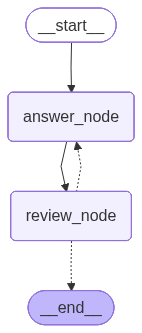

In [23]:
from IPython.display import Image, display
display(Image(graph.get_graph(xray=1).draw_mermaid_png()))

In [24]:
review_example = womens_reviews_df['Review Text'].iloc[0]
type(review_example)

str

In [25]:
graph.invoke(OverallState(review_text=review_example, sentiment="", reasoning="", agreement=False))

Processing first review. Generating sentiment analysis.
Reviewer agrees with the sentiment analysis or review count exceeded. Ending process.


{'review_text': 'Absolutely wonderful - silky and sexy and comfortable',
 'sentiment': 'good',
 'reasoning': "The review uses positive adjectives such as 'wonderful', 'silky', 'sexy', and 'comfortable', which all convey a strong sense of satisfaction and enjoyment. The overall tone is enthusiastic, indicating a very favorable opinion.",
 'agreement': True,
 'review_reasoning': "I agree with the sentiment of 'good' because the reasoning accurately identifies the use of positive adjectives that reflect satisfaction and enjoyment. The words 'wonderful', 'silky', 'sexy', and 'comfortable' indeed create an enthusiastic tone, supporting the conclusion that the review expresses a favorable opinion.",
 'review_count': 1}

In [26]:
graph.invoke({"review_text": review_example})

Processing first review. Generating sentiment analysis.
Reviewer agrees with the sentiment analysis or review count exceeded. Ending process.


{'review_text': 'Absolutely wonderful - silky and sexy and comfortable',
 'sentiment': 'good',
 'reasoning': "The review uses positive adjectives such as 'wonderful', 'silky', 'sexy', and 'comfortable', which all convey a strong sense of satisfaction and enjoyment. The overall tone is enthusiastic, indicating a very favorable opinion.",
 'agreement': True,
 'review_reasoning': "I agree with the sentiment of 'good' because the reasoning accurately identifies the use of positive adjectives that reflect satisfaction and enjoyment. The words 'wonderful', 'silky', 'sexy', and 'comfortable' indeed create an enthusiastic tone, supporting the conclusion that the review expresses a favorable opinion.",
 'review_count': 1}

In [28]:
sample_df = womens_reviews_df[['Review Text', 'Rating', 'Sentiment']].head(5)


In [29]:
sample_df

,Review Text,Rating,Sentiment
0,Absolutely wonderful - silky and sexy and comf...,4,good
1,Love this dress! it's sooo pretty. i happene...,5,good
2,I had such high hopes for this dress and reall...,3,neutral
3,"I love, love, love this jumpsuit. it's fun, fl...",5,good
4,This shirt is very flattering to all due to th...,5,good


In [30]:
inputs = [{"review_text": text} for text in sample_df['Review Text']]
results = graph.batch(inputs)

Processing first review. Generating sentiment analysis.
Processing first review. Generating sentiment analysis.
Processing first review. Generating sentiment analysis.
Processing first review. Generating sentiment analysis.
Processing first review. Generating sentiment analysis.
Reviewer agrees with the sentiment analysis or review count exceeded. Ending process.
Reviewer agrees with the sentiment analysis or review count exceeded. Ending process.
Reviewer agrees with the sentiment analysis or review count exceeded. Ending process.
Reviewer agrees with the sentiment analysis or review count exceeded. Ending process.
Reviewer agrees with the sentiment analysis or review count exceeded. Ending process.


In [31]:
results

[{'review_text': 'Absolutely wonderful - silky and sexy and comfortable',
  'sentiment': 'good',
  'reasoning': "The review uses positive adjectives such as 'wonderful', 'silky', 'sexy', and 'comfortable', which all convey a strong sense of satisfaction and enjoyment. The overall tone is enthusiastic, indicating a very favorable opinion.",
  'agreement': True,
  'review_reasoning': "I agree with the sentiment of 'good' because the reasoning accurately identifies the use of positive adjectives that reflect satisfaction and enjoyment. The words 'wonderful', 'silky', 'sexy', and 'comfortable' indeed create an enthusiastic tone, supporting the conclusion that the review expresses a favorable opinion.",
  'review_count': 1},
 {'review_text': 'Love this dress!  it\'s sooo pretty.  i happened to find it in a store, and i\'m glad i did bc i never would have ordered it online bc it\'s petite.  i bought a petite and am 5\'8".  i love the length on me- hits just a little below the knee.  would de

In [32]:
results_df = pd.DataFrame(results)
sample_final_df = pd.concat([sample_df, results_df], axis=1)
sample_final_df

,Review Text,Rating,Sentiment,review_text,sentiment,reasoning,agreement,review_reasoning,review_count
0,Absolutely wonderful - silky and sexy and comf...,4,good,Absolutely wonderful - silky and sexy and comf...,good,The review uses positive adjectives such as 'w...,True,I agree with the sentiment of 'good' because t...,1
1,Love this dress! it's sooo pretty. i happene...,5,good,Love this dress! it's sooo pretty. i happene...,good,The review expresses a strong positive sentime...,True,I agree with the sentiment of 'good' because t...,1
2,I had such high hopes for this dress and reall...,3,neutral,I had such high hopes for this dress and reall...,poor,The review expresses disappointment and frustr...,True,I agree with the sentiment of 'poor' because t...,1
3,"I love, love, love this jumpsuit. it's fun, fl...",5,good,"I love, love, love this jumpsuit. it's fun, fl...",good,The review expresses strong positive feelings ...,True,I agree with the sentiment of 'good' because t...,1
4,This shirt is very flattering to all due to th...,5,good,This shirt is very flattering to all due to th...,good,The review expresses positive feelings about t...,True,I agree with the sentiment of 'good' because t...,1


In [38]:
from sklearn.metrics import classification_report

print(classification_report(sample_final_df['Sentiment'], sample_final_df['sentiment']))

              precision    recall  f1-score   support

        good       1.00      1.00      1.00         4
     neutral       0.00      0.00      0.00         1
        poor       0.00      0.00      0.00         0

    accuracy                           0.80         5
   macro avg       0.33      0.33      0.33         5
weighted avg       0.80      0.80      0.80         5



/Users/adityanarvekar/agentic/agents/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/adityanarvekar/agentic/agents/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/adityanarvekar/agentic/agents/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modif

### exp-04 — independent critic

In [24]:
from pydantic import BaseModel, Field, field_validator, ValidationError

class InputState(BaseModel):
    review_text: str = Field(description="The text of the review to analyze.")

    @field_validator('review_text')
    def validate_review_text(cls, value):
        if not value or not isinstance(value, str):
            raise ValidationError("Review text must be a non-empty string.")
        return value

class OutputState(BaseModel):
    sentiment: str = Field(description="The sentiment of the review.")
    reasoning: str = Field(description="The reasoning for the sentiment analysis.")

class FinalState(BaseModel):
    final_sentiment: bool = Field(description="Whether the reviewer agrees with the sentiment based on the reasoning.")
    final_reasoning: str = Field(description="The reasoning provided by the reviewer for their agreement or disagreement.")
    @field_validator('final_sentiment')
    def validate_final_sentiment(cls, value):
        if not isinstance(value, bool):
            raise ValidationError("Final sentiment must be a boolean value.")
        return value


    
class OverallState_exp4(BaseModel):
    review_text: str = Field(description="The text of the review to analyze.")
    sentiment_1: str = Field(default="", description="The sentiment of the review for LLM 1.")
    reasoning_1: str = Field(default="", description="The reasoning for the sentiment analysis from LLM 1.")
    sentiment_2: str = Field(default="", description="The sentiment of the review for LLM 2.")
    reasoning_2: str = Field(default="", description="The reasoning for the sentiment analysis from LLM 2.")
    final_sentiment: str = Field(default="", description="The final sentiment of the review after considering both LLM analyses.")      

In [25]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

In [26]:
llm_answer = llm.with_structured_output(OutputState)

In [27]:
llm_review = llm.with_structured_output(FinalState)

In [67]:
def generate_answer1_exp4(state: OverallState_exp4):
    print ("Generating sentiment analysis from LLM 1")
    prompt = f"""
    Analyze the following review and determine its sentiment (good, neutral, or poor). Provide reasoning for your analysis.
    Review: {state.review_text}
    """
    response = llm_answer.invoke(prompt)
    sentiment = response.sentiment
    reasoning = response.reasoning
    return { 
        "sentiment_1": sentiment,
        "reasoning_1": reasoning,
    }

def generate_answer2_exp4(state: OverallState_exp4):
    print ("Generating sentiment analysis from LLM 2")
    prompt = f"""
    Analyze the following review and determine its sentiment (good, neutral, or poor). Provide reasoning for your analysis.
    Review: {state.review_text}
    """
    response = llm_answer.invoke(prompt)
    sentiment = response.sentiment
    reasoning = response.reasoning
    return { 
        "sentiment_2": sentiment,
        "reasoning_2": reasoning,
    }

In [69]:
def review_sentiment_analysis_exp4(state: OverallState_exp4):
    prompt = f"""Review the following sentiment analyses from two different LLMs and determine the final sentiment of the review. \
                 Consider the reasoning provided by both LLMs to make your decision.

    LLM 1 Sentiment: {state.sentiment_1}
    LLM 1 Reasoning: {state.reasoning_1}

    LLM 2 Sentiment: {state.sentiment_2}
    LLM 2 Reasoning: {state.reasoning_2}
    """
    response = llm_review.invoke(prompt)
    final_sentiment = response.final_sentiment
    final_reasoning = response.final_reasoning
    return {"final_sentiment": final_sentiment, "final_reasoning": final_reasoning}
    

In [70]:
def decide(state: OverallState_exp4):
    if state.sentiment_1 != state.sentiment_2:
        print("LLM 1 and LLM 2 have different sentiments. Proceeding to review node.")
        return {'final_sentiment': None, 'final_reasoning': None}  # Initialize final sentiment and reasoning for the review node
    else:        
        print("LLM 1 and LLM 2 have the same sentiment. Skipping review node.")
        return {}

In [71]:
def route_after_decide(state: OverallState_exp4):
    if state.sentiment_1 != state.sentiment_2:
        print("LLM 1 and LLM 2 have different sentiments. Proceeding to review node.")
        return 'review_node'
    else:        
        print("LLM 1 and LLM 2 have the same sentiment. Skipping review node.")
        return END

In [72]:
from langgraph.graph import START, END, StateGraph
# Build graph for experiment 4
builder_exp4 = StateGraph(OverallState_exp4)
builder_exp4.add_node('answer1_node', generate_answer1_exp4)
builder_exp4.add_node('answer2_node', generate_answer2_exp4)
builder_exp4.add_node('decide_node', decide)
builder_exp4.add_node('review_node', review_sentiment_analysis_exp4)
builder_exp4.add_edge(START, 'answer1_node')
builder_exp4.add_edge(START, 'answer2_node')
builder_exp4.add_edge('answer1_node', 'decide_node')
builder_exp4.add_edge('answer2_node', 'decide_node')
#builder_exp4.add_edge('decide_node', 'review_node')
builder_exp4.add_conditional_edges('decide_node', route_after_decide,['review_node', END])
builder_exp4.add_edge('review_node', END)
graph_exp4 = builder_exp4.compile()

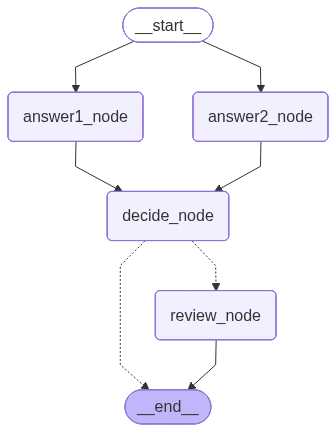

In [73]:
from IPython.display import Image, display
display(Image(graph_exp4.get_graph(xray=1).draw_mermaid_png()))

In [74]:
review_example = womens_reviews_df['Review Text'].iloc[0]
review_example

'Absolutely wonderful - silky and sexy and comfortable'

In [75]:
graph_exp4.invoke({"review_text": review_example})

Generating sentiment analysis from LLM 1
Generating sentiment analysis from LLM 2
LLM 1 and LLM 2 have the same sentiment. Skipping review node.
LLM 1 and LLM 2 have the same sentiment. Skipping review node.


{'review_text': 'Absolutely wonderful - silky and sexy and comfortable',
 'sentiment_1': 'good',
 'reasoning_1': "The review uses positive adjectives such as 'wonderful', 'silky', 'sexy', and 'comfortable', which all convey a strong sense of satisfaction and enjoyment. The overall tone is enthusiastic, indicating a very favorable opinion of the product.",
 'sentiment_2': 'good',
 'reasoning_2': "The review uses positive adjectives such as 'wonderful', 'silky', 'sexy', and 'comfortable', which all convey a strong sense of satisfaction and enjoyment. The overall tone is enthusiastic, indicating a very favorable opinion of the product."}

In [76]:
sample_df = womens_reviews_df[['Review Text', 'Rating', 'Sentiment']].head(5)

In [77]:
inputs = [{"review_text": text} for text in sample_df['Review Text']]
results = graph_exp4.batch(inputs)

Generating sentiment analysis from LLM 1
Generating sentiment analysis from LLM 1
Generating sentiment analysis from LLM 1
Generating sentiment analysis from LLM 1
Generating sentiment analysis from LLM 1
Generating sentiment analysis from LLM 2
Generating sentiment analysis from LLM 2
Generating sentiment analysis from LLM 2
Generating sentiment analysis from LLM 2
Generating sentiment analysis from LLM 2
LLM 1 and LLM 2 have the same sentiment. Skipping review node.
LLM 1 and LLM 2 have the same sentiment. Skipping review node.
LLM 1 and LLM 2 have the same sentiment. Skipping review node.
LLM 1 and LLM 2 have the same sentiment. Skipping review node.
LLM 1 and LLM 2 have the same sentiment. Skipping review node.
LLM 1 and LLM 2 have the same sentiment. Skipping review node.
LLM 1 and LLM 2 have the same sentiment. Skipping review node.
LLM 1 and LLM 2 have the same sentiment. Skipping review node.
LLM 1 and LLM 2 have the same sentiment. Skipping review node.
LLM 1 and LLM 2 have th

### exp-05 — self-consistency voting

In [83]:
from pydantic import BaseModel, Field, field_validator, ValidationError
from typing import List, Annotated
import operator

class InputState(BaseModel):
    review_text: str = Field(description="The text of the review to analyze.")

    @field_validator('review_text')
    def validate_review_text(cls, value):
        if not value or not isinstance(value, str):
            raise ValidationError("Review text must be a non-empty string.")
        return value

class OutputState(BaseModel):
    sentiment: str = Field(description="The sentiment of the review.")
    reasoning: str = Field(description="The reasoning for the sentiment analysis.")

class FinalState(BaseModel):
    final_sentiment: bool = Field(description="Whether the reviewer agrees with the sentiment based on the reasoning.")
    final_reasoning: str = Field(description="The reasoning provided by the reviewer for their agreement or disagreement.")
    @field_validator('final_sentiment')
    def validate_final_sentiment(cls, value):
        if not isinstance(value, bool):
            raise ValidationError("Final sentiment must be a boolean value.")
        return value


"""
class OverallState_exp5(BaseModel):
    review_text: str = Field(description="The text of the review to analyze.")
    sentiment_1: str = Field(default="", description="The sentiment of the review for LLM 1.")
    reasoning_1: str = Field(default="", description="The reasoning for the sentiment analysis from LLM 1.")
    sentiment_2: str = Field(default="", description="The sentiment of the review for LLM 2.")
    reasoning_2: str = Field(default="", description="The reasoning for the sentiment analysis from LLM 2.")
    sentiment_3: str = Field(default="", description="The sentiment of the review for LLM 3.")
    reasoning_3: str = Field(default="", description="The reasoning for the sentiment analysis from LLM 3.")
    sentiment_4: str = Field(default="", description="The sentiment of the review for LLM 4.")
    reasoning_4: str = Field(default="", description="The reasoning for the sentiment analysis from LLM 4.")
    sentiment_5: str = Field(default="", description="The sentiment of the review for LLM 5.")
    reasoning_5: str = Field(default="", description="The reasoning for the sentiment analysis from LLM 5.")
    final_sentiment: str = Field(default="", description="The final sentiment of the review after considering both LLM analyses.")      
"""

class OverallState_exp5(BaseModel):
    review_text: str = Field(description="The text of the review to analyze.")
    sentiment: Annotated[List[str],operator.add] = Field(default=[], description="The sentiment of the review for each LLM.")
    reasoning: Annotated[List[str], operator.add] = Field(default=[], description="The reasoning for the sentiment analysis from each LLM.")


In [79]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

llm_answer = llm.with_structured_output(OutputState)

In [102]:
def generate_answer_exp5(state: OverallState_exp5):
    #print ("Generating sentiment analysis from LLM ")
    prompt = f"""
    Analyze the following review and determine its sentiment (good, neutral, or poor). Provide reasoning for your analysis.
    Review: {state.review_text}
    """
    response = llm_answer.invoke(prompt)
    sentiment = response.sentiment
    reasoning = response.reasoning
    return { 
        "sentiment": [sentiment],
        "reasoning": [reasoning],
    }

In [92]:
def final_sentiment_exp5(state: OverallState_exp5):
    # count number of good, neutral, and poor sentiments in state.sentiment
    good_count = state.sentiment.count("good")
    neutral_count = state.sentiment.count("neutral")
    poor_count = state.sentiment.count("poor")

    # determine the final sentiment based on the counts
    if good_count > neutral_count and good_count > poor_count:
        final_sentiment = "good"
    elif neutral_count > poor_count:
        final_sentiment = "neutral"
    else:
        final_sentiment = "poor"

    final_reasoning = f"Based on the analyses from all LLMs, the final sentiment is determined to be {final_sentiment}."
    return {"final_sentiment": final_sentiment, "final_reasoning": final_reasoning}

In [94]:
from langgraph.graph import START, END, StateGraph
# Build graph for experiment 5
builder_exp5 = StateGraph(OverallState_exp5)
builder_exp5.add_node('answer_node_1', generate_answer_exp5)
builder_exp5.add_node('answer_node_2', generate_answer_exp5)
builder_exp5.add_node('answer_node_3', generate_answer_exp5)
builder_exp5.add_node('answer_node_4', generate_answer_exp5)
builder_exp5.add_node('answer_node_5', generate_answer_exp5)
builder_exp5.add_node('final_sentiment_node', final_sentiment_exp5)
builder_exp5.add_edge(START, 'answer_node_1')
builder_exp5.add_edge(START, 'answer_node_2')
builder_exp5.add_edge(START, 'answer_node_3')
builder_exp5.add_edge(START, 'answer_node_4')
builder_exp5.add_edge(START, 'answer_node_5')
builder_exp5.add_edge('answer_node_1', 'final_sentiment_node')
builder_exp5.add_edge('answer_node_2', 'final_sentiment_node')
builder_exp5.add_edge('answer_node_3', 'final_sentiment_node')
builder_exp5.add_edge('answer_node_4', 'final_sentiment_node')
builder_exp5.add_edge('answer_node_5', 'final_sentiment_node')
builder_exp5.add_edge('final_sentiment_node', END)
graph_exp5 = builder_exp5.compile()




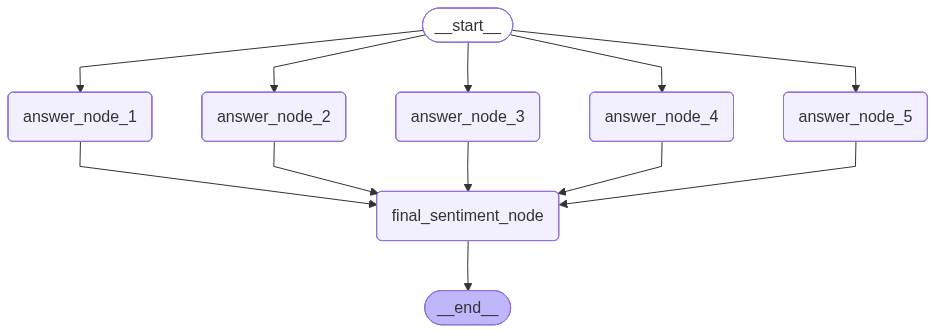

In [95]:
from IPython.display import Image, display
display(Image(graph_exp5.get_graph(xray=1).draw_mermaid_png()))

In [103]:
review_example = womens_reviews_df['Review Text'].iloc[0]
review_example

'Absolutely wonderful - silky and sexy and comfortable'

In [104]:
graph_exp5.invoke({"review_text": review_example})

Generating sentiment analysis from LLM Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 

Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 


{'review_text': 'Absolutely wonderful - silky and sexy and comfortable',
 'sentiment': ['good', 'good', 'good', 'good', 'good'],
 'reasoning': ["The review uses positive adjectives such as 'wonderful', 'silky', 'sexy', and 'comfortable', which all convey a strong sense of satisfaction and enjoyment. The overall tone is enthusiastic, indicating that the reviewer had a very positive experience.",
  "The review uses positive adjectives such as 'wonderful', 'silky', 'sexy', and 'comfortable', which all convey a strong sense of satisfaction and enjoyment. The overall tone is enthusiastic, indicating a very favorable opinion of the product.",
  "The review uses positive adjectives such as 'wonderful', 'silky', 'sexy', and 'comfortable', which all convey a strong sense of satisfaction and enjoyment. The overall tone is enthusiastic, indicating that the reviewer had a very positive experience.",
  "The review uses positive adjectives such as 'wonderful', 'silky', 'sexy', and 'comfortable', whi

In [98]:
sample_df = womens_reviews_df[['Review Text', 'Rating', 'Sentiment']].tail(5)

In [99]:
sample_df

,Review Text,Rating,Sentiment
23481,I was very happy to snag this dress at such a ...,5,good
23482,"It reminds me of maternity clothes. soft, stre...",3,neutral
23483,"This fit well, but the top was very see throug...",3,neutral
23484,I bought this dress for a wedding i have this ...,3,neutral
23485,This dress in a lovely platinum is feminine an...,5,good


In [105]:
inputs = [{"review_text": text} for text in sample_df['Review Text']]
results = graph_exp5.batch(inputs)
results_df

Generating sentiment analysis from LLM Generating sentiment analysis from LLM 

Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 
Generating sentiment analysis from LLM 


,review_text,sentiment,reasoning
0,I was very happy to snag this dress at such a ...,"[good, good, good, good, good]",[The review expresses happiness about purchasi...
1,"It reminds me of maternity clothes. soft, stre...","[neutral, neutral, neutral, neutral, neutral]",[The review expresses mixed feelings about the...
2,"This fit well, but the top was very see throug...","[neutral, neutral, neutral, neutral, neutral]",[The review expresses a mixed experience. The ...
3,I bought this dress for a wedding i have this ...,"[neutral, neutral, neutral, neutral, neutral]",[The review expresses mixed feelings about the...
4,This dress in a lovely platinum is feminine an...,"[good, good, good, good, good]",[The review expresses positive feelings about ...


In [106]:
results_df

,review_text,sentiment,reasoning
0,I was very happy to snag this dress at such a ...,"[good, good, good, good, good]",[The review expresses happiness about purchasi...
1,"It reminds me of maternity clothes. soft, stre...","[neutral, neutral, neutral, neutral, neutral]",[The review expresses mixed feelings about the...
2,"This fit well, but the top was very see throug...","[neutral, neutral, neutral, neutral, neutral]",[The review expresses a mixed experience. The ...
3,I bought this dress for a wedding i have this ...,"[neutral, neutral, neutral, neutral, neutral]",[The review expresses mixed feelings about the...
4,This dress in a lovely platinum is feminine an...,"[good, good, good, good, good]",[The review expresses positive feelings about ...


### Get log probs

In [109]:
from langchain_openai import ChatOpenAI
llm_logprobs = ChatOpenAI(model="gpt-4o-mini", temperature=0, logprobs=True)

In [110]:
review_example

'Absolutely wonderful - silky and sexy and comfortable'

In [113]:
response = llm_logprobs.invoke(review_example)

In [124]:
response.content

"It sounds like you're describing a luxurious fabric or perhaps a piece of clothing! Silky materials often evoke feelings of elegance and comfort, making them perfect for special occasions or cozy nights in. Is there a specific item or experience you're referring to?"

In [123]:
# get logprobs from response
response.response_metadata["logprobs"]

{'content': [{'token': 'It',
   'bytes': [73, 116],
   'logprob': -0.0006009306525811553,
   'top_logprobs': []},
  {'token': ' sounds',
   'bytes': [32, 115, 111, 117, 110, 100, 115],
   'logprob': -2.8921695047756657e-05,
   'top_logprobs': []},
  {'token': ' like',
   'bytes': [32, 108, 105, 107, 101],
   'logprob': 0.0,
   'top_logprobs': []},
  {'token': " you're",
   'bytes': [32, 121, 111, 117, 39, 114, 101],
   'logprob': -0.1269364058971405,
   'top_logprobs': []},
  {'token': ' describing',
   'bytes': [32, 100, 101, 115, 99, 114, 105, 98, 105, 110, 103],
   'logprob': -0.000570667558349669,
   'top_logprobs': []},
  {'token': ' a',
   'bytes': [32, 97],
   'logprob': -0.39856085181236267,
   'top_logprobs': []},
  {'token': ' luxurious',
   'bytes': [32, 108, 117, 120, 117, 114, 105, 111, 117, 115],
   'logprob': -0.17693929374217987,
   'top_logprobs': []},
  {'token': ' fabric',
   'bytes': [32, 102, 97, 98, 114, 105, 99],
   'logprob': -0.11126108467578888,
   'top_logpro

In [135]:
import numpy as np
#from pprint import pprint
for word in response.response_metadata["logprobs"]['content']:
    print(word['token'], np.round(np.exp(word['logprob'])*100,2), word['logprob'])

It 99.94 -0.0006009306525811553
 sounds 100.0 -2.8921695047756657e-05
 like 100.0 0.0
 you're 88.08 -0.1269364058971405
 describing 99.94 -0.000570667558349669
 a 67.13 -0.39856085181236267
 luxurious 83.78 -0.17693929374217987
 fabric 89.47 -0.11126108467578888
 or 99.4 -0.006012460216879845
 perhaps 46.77 -0.7599421143531799
 a 65.43 -0.4242241680622101
 piece 76.52 -0.26757705211639404
 of 100.0 0.0
 clothing 99.97 -0.000320330640533939
! 95.19 -0.0493139773607254
 Sil 50.47 -0.6837111711502075
ky 99.99 -5.3358446166384965e-05
 materials 52.36 -0.6471042633056641
 often 70.3 -0.3523865044116974
 evoke 54.25 -0.6116430163383484
 feelings 67.69 -0.3902919888496399
 of 100.0 0.0
 elegance 86.91 -0.1402609646320343
 and 99.59 -0.004081009421497583
 comfort 95.1 -0.050203777849674225
, 62.18 -0.47515538334846497
 making 90.85 -0.09593755006790161
 them 99.79 -0.002146812155842781
 perfect 70.84 -0.3447186350822449
 for 99.98 -0.00015920029545668513
 special 31.5 -1.155310034751892
 occas

In [ ]:
# convert logprobs to probabilities
import math


## Stratified sample    

In [145]:
womens_reviews_df.shape

(23486, 4)

In [146]:
womens_reviews_df.groupby('Sentiment').count()

,Title,Review Text,Rating
Sentiment,,,
good,15161,17448,18208
neutral,2464,2823,2871
poor,2051,2370,2407


In [150]:
stratified_womens_reviews_df = womens_reviews_df.groupby('Sentiment').sample(frac=0.25, random_state=42)

In [152]:
# Compute percentage of sentiments
total_reviews = len(stratified_womens_reviews_df)
sentiment_counts = stratified_womens_reviews_df['Sentiment'].value_counts()
sentiment_percentages = (sentiment_counts / total_reviews) * 100
print("Percentage of sentiments in stratified sample:")
print(sentiment_percentages)

Percentage of sentiments in stratified sample:
Sentiment
good       77.520436
neutral    12.227520
poor       10.252044
Name: count, dtype: float64
